## Cosmic Web - cuda.compute - Iterators

[cuda.compute](https://nvidia.github.io/cccl/python/) is the Python library of the CUDA Core Compute Libraries (CCCL). It provides ready-made GPU algorithms such as sorts and histograms, which run the C++ kernels of CUB. An algorithm can read an *iterator*, which computes each element on demand. We can then compute the births inside the library's kernel without storing them.

### Table of Contents

1. [Setup](#1-setup)
2. [Iterators](#2-iterators)
3. [Histogram](#3-histogram)
4. [Trace](#4-trace)
5. [Kernel in Python](#5-kernel-in-python)
6. [Limitations](#6-limitations)

---

### 1. Setup

We use the binned field as one flat array, so a voxel is one index $t$. cuda.compute reads CuPy arrays directly.

In [1]:
import importlib.metadata

import numpy as np
import cupy as cp
import cuda.compute as comp
import numba
from numba import cuda

import cosmic_core as cw

N, K = cw.setup('cccl', f'cuda-cccl {importlib.metadata.version("cuda-cccl")}, '
                        f'numba-cuda {importlib.metadata.version("numba-cuda")}')

N = 512^3, K = 128: 512 MiB of int32 on NVIDIA GeForce RTX 4080 SUPER; cuda-cccl 1.1.1, numba-cuda 0.30.4


### 2. Iterators

Let's build a cell's birth from its corners, one iterator on top of the other. An *op* is a Python function that the library compiles for the GPU. It may close over integers such as `n`, but arrays reach it only through iterators.

```text
CountingIterator(0)         t = 0, 1, 2, ...
  TransformIterator(op)     the neighbour's index
    PermutationIterator(q)  the field at that index: one corner
      ZipIterator(...)      all the corners of a cell
        TransformIterator   their minimum: the birth
```

Solution breakdown:

- **Find a corner's index.** `neighbour_index(di, dj, dk, n)` returns the op that maps voxel $t$ to the flat index of its corner at that offset, wrapping at the edge of the box.
- **Read the corner.** `corner(q, offset, n)` permutes `q` by those indices: the field value at every voxel's corner.
- **Take the minimum.** `births(q, n, corners)` zips the corners of a cell and applies `min2`, `min4` or `min8`.

`CELLS` lists each cell type's sign and the offsets of its corners.

---

**Quick Docs**

- `comp.CountingIterator(np.int32(start))`: `start, start + 1, ...`
- `comp.TransformIterator(underlying, op)`: `op(x)` for each element as it is read.
- `comp.PermutationIterator(values, indices)`: `values[i]` for each `i` the index iterator yields.
- `comp.ZipIterator(*iterators)`: a tuple per position, one element from each.

In [2]:
def neighbour_index(di, dj, dk, n):
    '''The op mapping voxel t to the flat index of its corner at offset (di, dj, dk), periodic.'''
    nn = n * n

    def op(t):
        i = t // nn
        j = (t - i * nn) // n
        k = t - i * nn - j * n
        # The offsets are 0 or 1, so one compare per axis wraps the index.
        i1 = i + di if i + di < n else 0
        j1 = j + dj if j + dj < n else 0
        k1 = k + dk if k + dk < n else 0
        return i1 * nn + j1 * n + k1
    return op


def corner(q, offset, n):
    '''The field read at every voxel's corner at `offset`: a permutation of q by the neighbour index.'''
    index = comp.TransformIterator(comp.CountingIterator(np.int32(0)), neighbour_index(*offset, n))
    return comp.PermutationIterator(q, index)


# One op per corner count: the zip tuple's length is fixed per cell type.
def min2(c): return min(c[0], c[1])
def min4(c): return min(min(c[0], c[1]), min(c[2], c[3]))
def min8(c): return min(min(min(c[0], c[1]), min(c[2], c[3])), min(min(c[4], c[5]), min(c[6], c[7])))

# Each cell type: its sign in the histogram and the offsets of its corners from the voxel.
CELLS = {
    'v':   (+1, [(0, 0, 0)]),
    'ex':  (-1, [(0, 0, 0), (1, 0, 0)]),
    'ey':  (-1, [(0, 0, 0), (0, 1, 0)]),
    'ez':  (-1, [(0, 0, 0), (0, 0, 1)]),
    # A face spans four corners: the voxel, its two edge neighbours and one diagonal neighbour.
    'fxy': (+1, [(0, 0, 0), (1, 0, 0), (0, 1, 0), (1, 1, 0)]),
    'fxz': (+1, [(0, 0, 0), (1, 0, 0), (0, 0, 1), (1, 0, 1)]),
    'fyz': (+1, [(0, 0, 0), (0, 1, 0), (0, 0, 1), (0, 1, 1)]),
    # The cube spans all eight.
    'c':   (-1, [(0, 0, 0), (1, 0, 0), (0, 1, 0), (1, 1, 0), (0, 0, 1), (1, 0, 1), (0, 1, 1), (1, 1, 1)]),
}


def births(q, n, corners):
    '''An iterator over the births of one cell type: the minimum of the field over the cell's corners.'''
    if len(corners) == 1:
        return q
    parts = [q] + [corner(q, c, n) for c in corners[1:]]
    return comp.TransformIterator(comp.ZipIterator(*parts), {2: min2, 4: min4, 8: min8}[len(corners)])

### 3. Histogram

Let's count the births with `histogram_even`. With $K + 1$ levels (bin boundaries) from $0$ to $K$, each bin covers one integer, so bin $b$ counts the births equal to $b$. The algorithm fills one histogram per call, so our eight cell types need eight passes over the field.

---

**Quick Docs**

- `comp.histogram_even(d_samples, d_histogram, num_output_levels, lower_level, upper_level, num_samples, stream)`: counts `num_samples` elements of `d_samples` into `num_output_levels - 1` bins between the two levels. Every argument is a keyword.
- `cp.cuda.get_current_stream()`: returns CuPy's current stream. Passing it orders the library's kernels after CuPy's.

In [3]:
def ecc_hist_cccl(samples, hists, n):
    '''Signed histogram of births (host int64, length K): one histogram_even per cell type into hists[name].'''
    stream = cp.cuda.get_current_stream()
    for name, it in samples.items():
        comp.histogram_even(d_samples=it, d_histogram=hists[name], num_output_levels=K + 1,
                            lower_level=np.int32(0), upper_level=np.int32(K), num_samples=n ** 3, stream=stream)
    # On the CPU, add the vertex and face counts and subtract the edge and cube counts.
    return sum(CELLS[name][0] * cp.asnumpy(hists[name]).astype(np.int64) for name in hists)


def cccl_state(n):
    '''The birth iterators and the histogram buffers for size n.'''
    q = cw.field(n).ravel()
    return ({name: births(q, n, corners) for name, (_, corners) in CELLS.items()},
            {name: cp.zeros(K, dtype=cp.int32) for name in CELLS})


def run_cccl(n):
    return ecc_hist_cccl(*STATE(n), n)

Now let's run a measurement.

In [4]:
STATE = cw.by_size(cccl_state)
_ = cw.measure('cccl', run_cccl, N, note='incl. the library building its kernels')

[cccl] N=512^3 K=128 | first call 12704.0 ms (incl. the library building its kernels) | median 13.8 ms = 9.718 Gvoxel/s | max|Δχ| 0 | PASS


### 4. Trace

How many kernels does the library launch per histogram, and how long does each pass take?

In [5]:
cells_src = 'CELLS = {\n' + '\n'.join(f'    {name!r}: {spec!r},' for name, spec in CELLS.items()) + '\n}'
trace = cw.trace_call('cccl', run_cccl, N, [neighbour_index, corner, min2, min4, min8, births, ecc_hist_cccl, cccl_state],
                      header='import cuda.compute as comp', state=[cells_src, STATE])
sweeps = [d for _, d, name, kind in trace['rows'] if kind == 'kernel' and 'Sweep' in name]  # the sweep kernel of each histogram
print('sweep kernel time per cell type (corners): '
      + ', '.join(f'{name} ({len(spec[1])}) {d * 1e3:.2f} ms' for (name, spec), d in zip(CELLS.items(), sweeps)))
cw.save_sweep('cccl', run_cccl)

[cccl] one call at N = 512^3: kernels 16, memcpys 8, memsets 0
sweep kernel time per cell type (corners): v (1) 0.78 ms, ex (2) 1.10 ms, ey (2) 0.81 ms, ez (2) 0.81 ms, fxy (4) 1.55 ms, fxz (4) 1.55 ms, fyz (4) 1.56 ms, c (8) 5.42 ms


  N=  64^3  median      0.35 ms    0.747 Gvoxel/s  max|Δχ| 0


  N= 128^3  median      0.40 ms    5.254 Gvoxel/s  max|Δχ| 0


  N= 256^3  median      1.55 ms   10.804 Gvoxel/s  max|Δχ| 0
  N= 512^3  median     13.83 ms    9.708 Gvoxel/s  max|Δχ| 0


- Each histogram runs two library kernels: an initialisation that zeroes the counters and a sweep that counts. The iterators run inside the sweep, so the trace shows only library kernels.
- The eight copies return the histograms to the CPU for the signed sum.
- The sweep time grows with the number of corners: each corner costs the kernel an index computation and a load.

### 5. Kernel in Python

The library ran eight passes over the field, one per cell type. Can one kernel do it in a single pass? Let's write it with [numba-cuda](https://nvidia.github.io/numba-cuda/), which compiles a Python function into a kernel at its first launch.

- **Map threads to voxels.** Thread $t$ takes voxel $t$ in memory order, so a warp loads consecutive addresses. Two divisions give $(i, j, k)$.
- **Compute births.** Each thread reads its eight corners and takes the eight births with `min`.
- **Count in shared memory.** Each thread block keeps its own histogram, as each slab did in JAX. Threads add $\pm 1$ at each birth bin.
- **Flush.** The block adds its non-zero bins into the global histogram: at most $K$ global atomic adds per block instead of eight per voxel.

The whole kernel is written below.

---

**Quick Docs**

- `@cuda.jit`: compiles the function. Globals such as `K` are fixed at compile time.
- `kernel[blocks, threads](*args)`: launches on `blocks` thread blocks of `threads` threads; CuPy arrays pass straight in. Inside, `cuda.grid(1)` gives the thread's index.
- `cuda.shared.array(shape, dtype)`: an array in the block's shared memory.
- `cuda.atomic.add(a, i, v)`, `cuda.atomic.sub(a, i, v)`: `a[i] += v` or `a[i] -= v` as one atomic operation, in shared or global memory.
- `cuda.syncthreads()`: a barrier over the block.

In [6]:
@cuda.jit
def ecc_hist_numba(q, hist, n):
    '''One thread per voxel: its eight births into the block's shared histogram, which the block adds into hist once.'''
    sh = cuda.shared.array(K, numba.int32)  # the block's own histogram
    for b in range(cuda.threadIdx.x, K, cuda.blockDim.x):
        sh[b] = 0
    cuda.syncthreads()
    t = cuda.grid(1)
    nn = n * n
    if t < nn * n:
        i = t // nn
        r = t - i * nn
        j = r // n
        k = r - j * n
        i1 = 0 if i + 1 == n else i + 1  # the periodic neighbours
        j1 = 0 if j + 1 == n else j + 1
        k1 = 0 if k + 1 == n else k + 1
        v000, v100 = q[i, j, k], q[i1, j, k]
        v010, v110 = q[i, j1, k], q[i1, j1, k]
        v001, v101 = q[i, j, k1], q[i1, j, k1]
        v011, v111 = q[i, j1, k1], q[i1, j1, k1]
        ex, ey, ez = min(v000, v100), min(v000, v010), min(v000, v001)
        fxy = min(ex, min(v010, v110))
        fxz = min(ex, min(v001, v101))
        fyz = min(ey, min(v001, v011))
        c = min(fxy, min(min(v001, v101), min(v011, v111)))
        cuda.atomic.add(sh, v000, 1)
        cuda.atomic.sub(sh, ex, 1)
        cuda.atomic.sub(sh, ey, 1)
        cuda.atomic.sub(sh, ez, 1)
        cuda.atomic.add(sh, fxy, 1)
        cuda.atomic.add(sh, fxz, 1)
        cuda.atomic.add(sh, fyz, 1)
        cuda.atomic.sub(sh, c, 1)
    cuda.syncthreads()
    for b in range(cuda.threadIdx.x, K, cuda.blockDim.x):  # the flush
        if sh[b] != 0:
            cuda.atomic.add(hist, b, sh[b])


BLOCK = 256


def run_numba(n):
    hist = cp.zeros(K, dtype=cp.int32)
    # The launch goes on the default stream, as the memset above.
    ecc_hist_numba[(n ** 3 + BLOCK - 1) // BLOCK, BLOCK](cw.field(n), hist, n)
    cp.cuda.get_current_stream().synchronize()
    return cp.asnumpy(hist).astype(np.int64)

Now let's run a measurement.

[numba] N=512^3 K=128 | first call 99.1 ms (incl. the numba compile) | median 2.5 ms = 53.759 Gvoxel/s | max|Δχ| 0 | PASS
[numba] median 2.5 ms against [cccl] 13.8 ms: 5.5 x faster


one call at N = 512^3                 cuda.compute    numba-cuda
kernels                                         16             1
memcpys                                          8             1
memsets                                          0             1


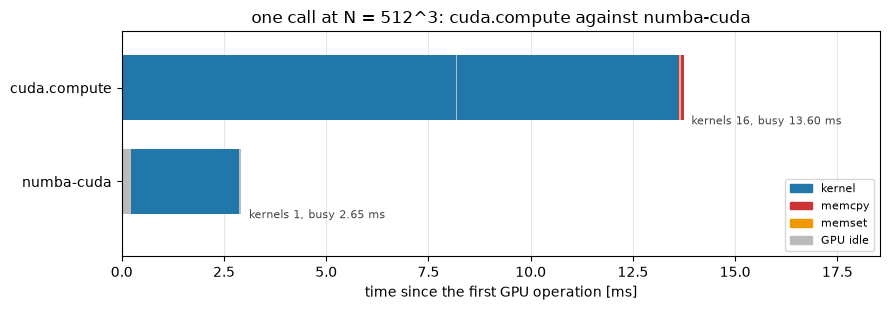

  N=  64^3  median      0.07 ms    3.677 Gvoxel/s  max|Δχ| 0
  N= 128^3  median      0.10 ms   20.544 Gvoxel/s  max|Δχ| 0
  N= 256^3  median      0.39 ms   43.527 Gvoxel/s  max|Δχ| 0
  N= 512^3  median      2.63 ms   50.946 Gvoxel/s  max|Δχ| 0


In [7]:
cw.measure('numba', run_numba, N, note='incl. the numba compile')
cw.compare('numba', 'cccl')

trace_numba = cw.trace_call('numba', run_numba, N, [ecc_hist_numba], header='import numba\nfrom numba import cuda',
                            state=[f'BLOCK = {BLOCK}'], quiet=True)
calls = {'cuda.compute': trace, 'numba-cuda': trace_numba}
cw.call_table(calls)
cw.plot_timelines(calls, title=f'one call at N = {N}^3: cuda.compute against numba-cuda')
cw.save_sweep('numba', run_numba)

Takeaways:

- The library's kernel reads each corner through the iterators as it runs, so the births are never stored.
- `@cuda.jit` compiled a one-pass kernel from Python, with one histogram per thread block in shared memory.

### 6. Limitations

cuda.compute provides the kernel, its thread mapping and one histogram per call. numba-cuda gives us control over those features, within the subset of Python it compiles.

Next: `94__cosmic_web__cppjit__cuda_kernel.ipynb` calls CUB's histogram from C++, then writes the same algorithm in CUDA C++.